# Ejercicio 0 · PLANTILLA · ¿Qué socios se darán de baja del gimnasio?
## Árbol frente a Random Forest, AdaBoost y XGBoost

**Módulo 5072 · SAA · UD3 · Métodos ensemble** · Notebook resuelto para trabajar en clase (45 min).

Ya conocéis estos datos: los usamos para aprender validación cruzada y `GridSearchCV`. Por eso aquí solo hay una cosa nueva: **los ensembles**. 

| Paso | Qué hacemos | Teoría de la presentación |
|---|---|---|
| 1-3 | Datos, test aparte, validación cruzada y baseline | Lo que ya sabéis |
| 4 | El árbol: sin límite y ajustado | El punto de partida |
| 5 | Bagging con cualquier modelo y Random Forest | Bagging: bolsas + votación; Random Forest añade el sorteo de variables |
| 6 | AdaBoost y XGBoost | Boosting: cada modelo corrige al anterior |
| 7-8 | Tabla comparativa y elección | Elegimos con validación cruzada |
| 9 | Test, una sola vez | El test solo confirma |

## 0 · Preparación

Cargamos las librerías y fijamos la `SEMILLA`. Con la misma semilla, todos los sorteos (el reparto train/test, los 5 trozos, las bolsas del bagging) salen igual cada vez: todos obtenemos los mismos números.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import f1_score, recall_score, precision_score, roc_auc_score, confusion_matrix, RocCurveDisplay
from xgboost import XGBClassifier      # si falla: pip install xgboost

DATA = "../data/"
SEMILLA = 42

## 1 · El problema y los datos

Una cadena de gimnasios quiere saber qué socios se van a dar de baja **antes** de que lo hagan, para llamarles con una oferta. Cada fila es un socio; `baja = 1` significa que se dio de baja.

- **Clase positiva:** `baja = 1`. Es la que queremos encontrar.
- **Error caro:** no detectar a alguien que se va (falso negativo) ( **recall** ).
- **Métrica para elegir:** **F1**, que equilibra recall y precision. Miramos también el **AUC**.

In [7]:
df = pd.read_csv(DATA + "gimnasio_bajas.csv")
print(df.shape)


(1000, 7)


In [8]:
df.head()

,visitas_semana,meses_socio,edad,clases_grupales,tarifa_premium,distancia_km,baja
0,1.9,5,24,1,0,2.0,0
1,4.1,4,58,1,1,6.7,1
2,1.5,22,59,1,0,11.8,0
3,2.8,8,33,0,0,7.3,1
4,3.1,10,68,1,1,4.8,1


In [9]:
print(df["baja"].value_counts(normalize=True).round(3))


baja
0    0.591
1    0.409
Name: proportion, dtype: float64


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   visitas_semana   1000 non-null   float64
 1   meses_socio      1000 non-null   int64  
 2   edad             1000 non-null   int64  
 3   clases_grupales  1000 non-null   int64  
 4   tarifa_premium   1000 non-null   int64  
 5   distancia_km     1000 non-null   float64
 6   baja             1000 non-null   int64  
dtypes: float64(2), int64(5)
memory usage: 54.8 KB


1.000 socios, 6 variables numéricas, sin huecos. El 41 % se da de baja: las clases están bastante equilibradas.

## 2 · Test aparte y validación cruzada

Apartamos 200 socios para el examen final (test) y no los miramos hasta el paso 9. Con los otros 800 entrenamos y validamos.

- `X`: lo que sabemos de cada socio (visitas, meses, edad…).
- `y`: lo que queremos predecir, si se da de baja.
- `stratify=y`: en train y en test queda el mismo porcentaje de bajas (41 %).

In [11]:
X = df.drop(columns="baja")
y = df["baja"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA)



In [12]:
y_test.value_counts(normalize=True).round(3)

baja
0    0.59
1    0.41
Name: proportion, dtype: float64

In [13]:
y_train.value_counts(normalize=True).round(3)

baja
0    0.591
1    0.409
Name: proportion, dtype: float64

`cv` es el reparto en 5 trozos. Lo usamos para **todos** los modelos del notebook: así todos se examinan con los mismos socios y la comparación es justa.

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
print(len(X_train), "socios para entrenar y validar ·", len(X_test), "para el test final")

800 socios para entrenar y validar · 200 para el test final


> **Para entenderlo · ¿Dónde está la validación?**
>
> Seguimos usando train, validación y test:
>
> - **Test (200 socios):** se aparta ahora y no se toca hasta el paso 9.
> - **Validación:** no es un trozo fijo. La validación cruzada parte los 800 socios del train en 5 trozos, y cada trozo hace de validación una vez mientras los otros 4 entrenan.
>
> ¿Por qué no un trozo fijo? Con 800 socios, una validación fija tendría 160 y el resultado dependería mucho de qué socios cayeran en ella. Con 5 trozos, todos los socios validan una vez y además obtenemos la desviación, que es lo que nos dice si una diferencia entre modelos es real.
>
> `GridSearchCV` hace lo mismo por dentro: prueba cada combinación con los 5 trozos.

La función `evaluar()` hace la validación cruzada y devuelve una fila de la tabla. Además del F1 en validación, guarda el **F1 en train**: si el F1 en train es mucho mayor que en validación, el modelo memoriza.

In [15]:
def evaluar(nombre, modelo):
     # Hace validación cruzada: entrena 5 veces (una por trozo) y mide F1, recall y AUC en cada una.
    # OJO: scikit-learn las llama "test_...", pero son del trozo de VALIDACIÓN de cada ronda.
    # El test de verdad (X_test, y_test) sigue guardado hasta el final.

    # No deja un modelo entrenado: mide y tira esos 5 modelos. Solo sirve para ponerle nota.

    # Usamos validación cruzada porque tenemos pocos datos (800 socios):
    # la nota es más fiable y el ± nos dice si una diferencia es un empate.
    r = cross_validate(modelo, X_train, y_train, cv=cv,
                       scoring=["f1", "recall", "roc_auc"], return_train_score=True)

    print(r)
    return {"modelo": nombre,
            "F1 val": r["test_f1"].mean(),        # validación (media de los 5 trozos)
            "± F1 val": r["test_f1"].std(),
            "recall val": r["test_recall"].mean(),
            "AUC val": r["test_roc_auc"].mean(),
            "F1 train": r["train_f1"].mean()}    # train: si es mucho mayor, memoriza

resultados = []

**Cómo leer la tabla**
- `F1 val`: la nota del modelo con socios que no ha visto (media de los 5 trozos de validación). Es la que usamos para comparar.
- `± F1 val`: cuánto cambia esa nota de un trozo a otro. Si dos modelos se diferencian menos que esto, es un empate.
- `recall val`: de cada 100 socios que se dan de baja, cuántos detecta.
- `AUC val`: si sabe poner a los que se van por delante de los que se quedan (0,5 = al azar, 1 = perfecto).
- `F1 train`: la nota con los socios que ya ha visto. Si es mucho más alta que `F1 val` (por ejemplo, 1,00 frente a 0,61), se ha aprendido el train de memoria.

## 3 · Baseline: decir siempre la clase más frecuente

Lo calculamos a mano, como en las tareas anteriores. Como la clase más frecuente es «no se da de baja», el baseline no encuentra a nadie: F1 = 0 y AUC = 0,5.

In [16]:
y_train.value_counts(normalize=True).round(3)

baja
0    0.591
1    0.409
Name: proportion, dtype: float64

`pred_base` dice «no se da de baja» para todos los socios. Es el modelo más tonto posible: cualquier modelo que usemos tiene que ganarle.

In [17]:
pred_base = np.full(len(y_train), y_train.mode()[0])  # la clase mayoritaria  - 


In [18]:
resultados.append({"modelo": "Baseline (siempre 'no')",
                   "F1 val": f1_score(y_train, pred_base), "± F1 val": np.nan,
                   "recall val": recall_score(y_train, pred_base), "AUC val": 0.5,
                   "F1 train": f1_score(y_train, pred_base)})


## 4 · El punto de partida: un árbol

### Árbol sin límite

Un árbol sin frenos sigue preguntando hasta que cada hoja tiene socios de una sola clase. Vamos a ver si eso es aprender o memorizar: compara `F1 train` con `F1 val`.

In [19]:
resultados.append(evaluar("Árbol sin límite", DecisionTreeClassifier(random_state=SEMILLA)))
pd.DataFrame(resultados).round(3)

{'fit_time': array([0.0090878 , 0.00299978, 0.00247622, 0.00300026, 0.00234103]), 'score_time': array([0.01242971, 0.00883317, 0.00803065, 0.00699902, 0.00600743]), 'test_f1': array([0.62857143, 0.56115108, 0.69291339, 0.6870229 , 0.50769231]), 'train_f1': array([1., 1., 1., 1., 1.]), 'test_recall': array([0.67692308, 0.6       , 0.67692308, 0.68181818, 0.5       ]), 'train_recall': array([1., 1., 1., 1., 1.]), 'test_roc_auc': array([0.67530364, 0.61578947, 0.7437247 , 0.73452611, 0.58510638]), 'train_roc_auc': array([1., 1., 1., 1., 1.])}


,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Baseline (siempre 'no'),0.000,NaN,0.000,0.500,0.0
1,Árbol sin límite,0.615,0.072,0.627,0.671,1.0


In [20]:
pd.DataFrame(resultados).round(3)

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Baseline (siempre 'no'),0.000,NaN,0.000,0.500,0.0
1,Árbol sin límite,0.615,0.072,0.627,0.671,1.0


**¿Qué es el `± F1 val`?** Cuánto cambia la nota de un trozo de validación a otro


### Árbol ajustado

1- Vamos a buscar los mejores hiperparámetros con GridSearch

2- Entrenamos un nuevo árbol con los mejores hiperparámetros encontrados

3- La métrica que elegimos para encontrar esos mejores hiperparámetros es "f1". Estamos clasificando y queremos encontrar a los que se van.


In [21]:
gs_arbol = GridSearchCV(DecisionTreeClassifier(random_state=SEMILLA),
                        {"max_depth": [2, 3, 4, 5, 6, 8], "min_samples_leaf": [2, 5, 10, 20]},
                        cv=cv, scoring="f1")
gs_arbol.fit(X_train, y_train)
print("Mejores hiperparámetros:", gs_arbol.best_params_)


Mejores hiperparámetros: {'max_depth': 3, 'min_samples_leaf': 2}


### Evaluamos el mejor árbol que ya nos lo da GridSearch

In [22]:
resultados.append(evaluar("Árbol ajustado", gs_arbol.best_estimator_))
pd.DataFrame(resultados).round(3)

{'fit_time': array([0.00152683, 0.00300312, 0.00200129, 0.00200009, 0.00200105]), 'score_time': array([0.01424837, 0.00700045, 0.00599885, 0.00600028, 0.00599837]), 'test_f1': array([0.73684211, 0.7518797 , 0.74015748, 0.76666667, 0.64      ]), 'train_f1': array([0.73852295, 0.74329502, 0.73622047, 0.72189349, 0.75298805]), 'test_recall': array([0.75384615, 0.76923077, 0.72307692, 0.6969697 , 0.60606061]), 'train_recall': array([0.70610687, 0.74045802, 0.71374046, 0.70114943, 0.72413793]), 'test_roc_auc': array([0.82356275, 0.82850202, 0.8340081 , 0.83945841, 0.74661509]), 'train_roc_auc': array([0.83995214, 0.83301022, 0.83446928, 0.83448074, 0.85712553])}


,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Baseline (siempre 'no'),0.000,NaN,0.000,0.500,0.000
1,Árbol sin límite,0.615,0.072,0.627,0.671,1.000
2,Árbol ajustado,0.727,0.045,0.710,0.814,0.739


**Qué vemos.** 

- El árbol sin límite saca F1 = 1,000 en train y 0,615 en validación: memoriza. 

- El árbol ajustado (profundidad 3) baja en train, pero sube a 0,727 en validación. Podar ayuda.

## 5 · Bagging

Primero vemos que el bagging sirve con cualquier modelo. Después, Random Forest - que es un tipo de Bagging

### Bagging con cualquier modelo

> **Para entenderlo · Bagging con cualquier modelo**
>
> Bagging es una idea general: **muchas copias del mismo modelo, cada una entrenada con su bolsa de datos, y votan**. El modelo puede ser cualquiera.
>
> En scikit-learn se hace con `BaggingClassifier`: le dices qué modelo copiar (`estimator`) y cuántas copias hacer (`n_estimators`).
>
> Lo probamos con dos modelos que ya conocéis:
> - una **regresión logística**, que es un modelo estable;
> - un **árbol sin límite**, que cambia de opinión con poco.
>
> ¿Ayuda el bagging igual a los dos?

In [23]:
from sklearn.ensemble import BaggingClassifier
from sklearn.linear_model import LogisticRegression

#### Paso 1 · Un modelo estable: la regresión logística

Evaluamos una logística sola y un bagging de 300 logísticas. Cada copia se entrena con su bolsa de socios y al final se hace la media de lo que dicen las 300.

**Antes de ejecutar:** ¿creéis que 300 logísticas acertarán más que una?

In [24]:
logistica = LogisticRegression(max_iter=1000)   # la regresión logística de siempre



In [25]:
bagging_logistica = [
    evaluar("Regresión logística (1 modelo)", logistica),
    evaluar("Bagging de 300 regresiones logísticas",

            #n_jobs dice cuántos núcleos del procesador trabajan a la vez.
            # n_jobs=1 (el valor por defecto): un solo núcleo. Entrena las 300 copias una detrás de otra.
            # n_jobs=-1: todos los núcleos del ordenador. Si tiene 300 núcleos, entrena 300 copias a la vez. 
            # con -1, mientras se ejecuta la celda el ordenador va más lento para otras cosas.
            BaggingClassifier(estimator=logistica, n_estimators=300, random_state=SEMILLA, n_jobs=-1)),
]
pd.DataFrame(bagging_logistica).round(3)

{'fit_time': array([0.02088356, 0.01350307, 0.00997949, 0.01037002, 0.01308751]), 'score_time': array([0.006006  , 0.00964403, 0.00643182, 0.00600934, 0.00602865]), 'test_f1': array([0.656     , 0.70967742, 0.625     , 0.736     , 0.62015504]), 'train_f1': array([0.68897638, 0.65714286, 0.69184891, 0.65306122, 0.72111554]), 'test_recall': array([0.63076923, 0.67692308, 0.53846154, 0.6969697 , 0.60606061]), 'train_recall': array([0.66793893, 0.61450382, 0.66412214, 0.61302682, 0.69348659]), 'test_roc_auc': array([0.74979757, 0.83789474, 0.76080972, 0.8030303 , 0.70245003]), 'train_roc_auc': array([0.78291732, 0.7602387 , 0.78457329, 0.77033735, 0.80224224])}
{'fit_time': array([5.78347135, 0.29429984, 0.29441714, 0.40435028, 0.39827108]), 'score_time': array([0.08994365, 0.07571912, 0.07809758, 0.07927823, 0.09414673]), 'test_f1': array([0.656     , 0.69918699, 0.625     , 0.74603175, 0.62015504]), 'train_f1': array([0.68762279, 0.65439673, 0.69047619, 0.65163934, 0.72144289]), 'test_re

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Regresión logística (1 modelo),0.669,0.046,0.63,0.771,0.682
1,Bagging de 300 regresiones logísticas,0.669,0.048,0.63,0.771,0.681


---
**Qué vemos.** Una logística sola saca 0,669 y el bagging de 300 logísticas, 0,669. No mejora nada.

¿Por qué? La logística es un modelo **estable**: aprende una fórmula usando todos los socios a la vez, así que si le cambias unos cuantos socios, la fórmula casi no cambia. Las 300 copias ven bolsas distintas, pero aprenden casi la misma fórmula.

Si todas dicen casi lo mismo, la media dice lo mismo que una sola. **Juntar 300 opiniones iguales no aporta nada nuevo.**


#### Paso 2 · Un modelo inestable: el árbol sin límite

Ahora lo mismo con el árbol sin límite del paso 4, el que memoriza. Cada árbol se aprende su bolsa de memoria, y como las bolsas son distintas, cada uno se equivoca en socios distintos.


In [26]:
arbol = DecisionTreeClassifier(random_state=SEMILLA)

bagging_arbol = [
    evaluar("Árbol sin límite (1 modelo)", arbol),
    evaluar("Bagging de 300 árboles",
            BaggingClassifier(estimator=arbol, n_estimators=300, random_state=SEMILLA, n_jobs=-1)),
]
pd.DataFrame(bagging_arbol).round(3)

{'fit_time': array([0.00399208, 0.00399995, 0.00200891, 0.00200391, 0.00200748]), 'score_time': array([0.00701165, 0.00767493, 0.00599909, 0.00593305, 0.00600076]), 'test_f1': array([0.62857143, 0.56115108, 0.69291339, 0.6870229 , 0.50769231]), 'train_f1': array([1., 1., 1., 1., 1.]), 'test_recall': array([0.67692308, 0.6       , 0.67692308, 0.68181818, 0.5       ]), 'train_recall': array([1., 1., 1., 1., 1.]), 'test_roc_auc': array([0.67530364, 0.61578947, 0.7437247 , 0.73452611, 0.58510638]), 'train_roc_auc': array([1., 1., 1., 1., 1.])}
{'fit_time': array([0.10602856, 0.09435248, 0.08479714, 0.08668184, 0.09349418]), 'score_time': array([0.12112641, 0.10882449, 0.10741258, 0.12589025, 0.14026284]), 'test_f1': array([0.67692308, 0.66141732, 0.71428571, 0.69421488, 0.62903226]), 'train_f1': array([1., 1., 1., 1., 1.]), 'test_recall': array([0.67692308, 0.64615385, 0.69230769, 0.63636364, 0.59090909]), 'train_recall': array([1., 1., 1., 1., 1.]), 'test_roc_auc': array([0.80963563, 0.80

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Árbol sin límite (1 modelo),0.615,0.072,0.627,0.671,1.0
1,Bagging de 300 árboles,0.675,0.029,0.649,0.789,1.0


**Qué vemos.** 

- De 0,615 a 0,675 en validación, y el `± F1 val` baja de 0,072 a 0,029: acierta más y además es más estable.

- `F1 train` sigue en 1,000 porque cada árbol memoriza su bolsa, pero cada uno se equivoca en socios distintos y la votación tapa esos errores.

#### Paso 3 · Las dos juntas

In [27]:
pd.DataFrame(bagging_logistica + bagging_arbol).round(3)

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Regresión logística (1 modelo),0.669,0.046,0.630,0.771,0.682
1,Bagging de 300 regresiones logísticas,0.669,0.048,0.630,0.771,0.681
2,Árbol sin límite (1 modelo),0.615,0.072,0.627,0.671,1.000
3,Bagging de 300 árboles,0.675,0.029,0.649,0.789,1.000


**Conclusión.** 

- El bagging solo ayuda a los modelos que cambian mucho de opinión con los datos (inestables), como el árbol. 

- A un modelo estable, como la logística, no le aporta nada. Por eso el bagging casi siempre se hace con árboles. 

### Random Forest

Random Forest es bagging de árboles más el sorteo de variables. Lo probamos primero con los valores por defecto y después ajustando dos hiperparámetros:

- `max_features`: cuántas variables sortea cada pregunta (el sorteo extra de Random Forest).
- `min_samples_leaf`: el freno de siempre, mínimo de socios por hoja.

> **Para entenderlo · Los hiperparámetros de Random Forest**
>
> | Hiperparámetro | Qué controla | Si lo subes… |
> |---|---|---|
> | `n_estimators` | Cuántos árboles votan | El bosque es más estable y tarda más. Si pones demasiados, no memoriza más |
> | `max_features` | Entre cuántas variables puede elegir cada pregunta del árbol  |Si lo subes, todos los árboles preguntan por las mismas variables y votan casi igual: votar ayuda poco. Si lo bajas, cada árbol se fija en cosas distintas y votar ayuda más. Pero si lo bajas demasiado, muchas preguntas tienen que elegir entre variables que no sirven: cada árbol acierta poco y la votación no lo arregla. El valor bueno está en medio y se elige con `GridSearchCV`. |
> | `min_samples_leaf` | Mínimo de filas en cada hoja | Árboles más simples: se aprenden menos el train de memoria. |
>
> En Random Forest los árboles pueden ser grandes porque se hace la media de todos: los errores de uno los tapan los demás.

El gimnasio tiene 6 variables: visitas_semana, meses_socio, edad, clases_grupales, tarifa_premium y distancia_km.

Para **max_features** prueba esos tres valores:

- "sqrt": la raíz de 6 (Raíz de 6 = 2,45, se queda la parte entera), es decir, 2 variables.
- 0.5: la mitad (La mitad: 0,5 × 6 = 3), 3 variables.
- 1.0: todas, 6 variables.

#### Random Forest por defecto

300 árboles sin límite, cada uno con su bolsa y con sorteo de variables: por defecto, cada pregunta elige entre 2 de las 6 (`max_features="sqrt"`).

In [28]:
resultados.append(evaluar("Random Forest por defecto",
                          RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=-1)))
pd.DataFrame(resultados).round(3)

{'fit_time': array([0.42696428, 0.38075876, 0.36452651, 0.3753016 , 0.37616205]), 'score_time': array([0.11099863, 0.1018033 , 0.11104345, 0.11150718, 0.09873223]), 'test_f1': array([0.67164179, 0.688     , 0.74193548, 0.72131148, 0.64566929]), 'train_f1': array([1., 1., 1., 1., 1.]), 'test_recall': array([0.69230769, 0.66153846, 0.70769231, 0.66666667, 0.62121212]), 'train_recall': array([1., 1., 1., 1., 1.]), 'test_roc_auc': array([0.80882591, 0.83311741, 0.82963563, 0.81262089, 0.71598968]), 'train_roc_auc': array([1., 1., 1., 1., 1.])}


,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Baseline (siempre 'no'),0.000,NaN,0.000,0.500,0.000
1,Árbol sin límite,0.615,0.072,0.627,0.671,1.000
2,Árbol ajustado,0.727,0.045,0.710,0.814,0.739
3,Random Forest por defecto,0.694,0.034,0.670,0.800,1.000


**Qué vemos.** Random Forest por defecto también saca 1,000 en train: sus árboles no tienen límite. Pero en validación (0,694) ya supera al árbol sin límite (0,615): la votación quita parte de la memoria.

#### Random Forest ajustado

`GridSearchCV` prueba 3 valores de `max_features` × 3 de `min_samples_leaf` = 9 bosques, cada uno validado con los 5 trozos, y se queda con el de mejor F1.

In [29]:
gs_rf = GridSearchCV(RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=-1),
                     {"max_features": ["sqrt", 0.5, 1.0], "min_samples_leaf": [2, 5, 10]},
                     cv=cv, scoring="f1")
gs_rf.fit(X_train, y_train)
print("Mejores hiperparámetros:", gs_rf.best_params_)



Mejores hiperparámetros: {'max_features': 'sqrt', 'min_samples_leaf': 10}


**Qué vemos.** Gana `max_features="sqrt"` (2 variables por pregunta) con hojas de al menos 10 socios: 0,730 en validación, y en train baja de 1,000 a 0,772. El freno de las hojas quita memoria.


In [30]:
# GridSearchCV ya validó este modelo con los mismos 5 trozos (gs_rf.best_score_ = 0,730).
# Volvemos a llamar a evaluar() solo para tener la fila completa en la tabla:
# sale exactamente el mismo F1. Repite trabajo, pero así todas las filas se calculan igual.

resultados.append(evaluar("Random Forest ajustado", gs_rf.best_estimator_))
pd.DataFrame(resultados).round(3)

{'fit_time': array([0.38459468, 0.37712812, 0.49394846, 0.40752792, 0.42023635]), 'score_time': array([0.109097  , 0.1130271 , 0.12286067, 0.20645952, 0.11644554]), 'test_f1': array([0.71942446, 0.76335878, 0.74015748, 0.7804878 , 0.64566929]), 'train_f1': array([0.77906977, 0.76744186, 0.76377953, 0.7592955 , 0.79078695]), 'test_recall': array([0.76923077, 0.76923077, 0.72307692, 0.72727273, 0.62121212]), 'train_recall': array([0.76717557, 0.75572519, 0.74045802, 0.74329502, 0.78927203]), 'test_roc_auc': array([0.83676113, 0.85813765, 0.83757085, 0.82817537, 0.73275306]), 'train_roc_auc': array([0.90984087, 0.90699342, 0.90863928, 0.9067621 , 0.92349296])}


,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Baseline (siempre 'no'),0.000,NaN,0.000,0.500,0.000
1,Árbol sin límite,0.615,0.072,0.627,0.671,1.000
2,Árbol ajustado,0.727,0.045,0.710,0.814,0.739
3,Random Forest por defecto,0.694,0.034,0.670,0.800,1.000
4,Random Forest ajustado,0.730,0.047,0.722,0.819,0.772



### ¿Qué variables usa el bosque?

La importancia mide cuánto ayuda cada variable a separar a los que se van de los que se quedan, sumado en los 300 árboles. Barra larga = variable muy usada.

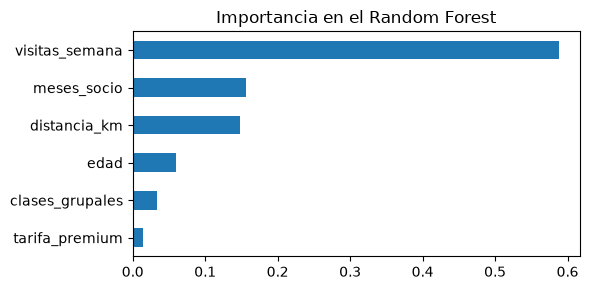

In [31]:
importancias = pd.Series(gs_rf.best_estimator_.feature_importances_, index=X.columns).sort_values()
importancias.plot.barh(figsize=(6, 3), title="Importancia en el Random Forest")
plt.tight_layout(); plt.show()

## 6 · Boosting: AdaBoost y XGBoost

- **AdaBoost**: cada árbol pequeño se fija más en los socios que falló el anterior.
- **XGBoost**: cada árbol pone un parche a lo que le falta a la predicción.

Probamos XGBoost primero con los valores por defecto (100 árboles de profundidad 6) y después con frenos.

> **Para entenderlo · Los hiperparámetros de XGBoost**
>
> Cada árbol es un **parche** que corrige lo que les falta a los anteriores (la tasación del piso de la presentación).
>
> | Hiperparámetro | Qué controla | En la tasación | Por defecto |
> |---|---|---|---|
> | `n_estimators` | Cuántos árboles (parches) | Pocos: el precio se queda corto. Demasiados: los últimos corrigen casualidades del train y el modelo memoriza. **Ojo!!!!** puede memorizar si poenes demasiados: cada árbol nuevo sigue corrigiendo, y los últimos corrigen casualidades del train. Por eso sí se busca. | 100 |
> | `learning_rate` | **Cuánto caso le hacemos a cada árbol**: qué parte de su corrección se suma | El árbol dice «+40.000 € por el garaje». Con 0,1 solo sumamos 4.000 y el siguiente sigue corrigiendo. Si ese árbol se equivocaba, se nota poco. | 0,3 |
> | `max_depth` | Cuántas preguntas seguidas hace cada árbol | Con 3: «¿garaje? → ¿piso alto? → ¿exterior?», una regla general. Con 10 acaba describiendo un piso concreto. | 6 |
>
> Dos reglas:
> 1. **Los frenos son `learning_rate` pequeño y `max_depth` pequeño** (2 a 4). Con los valores por defecto le hace mucho caso a cada árbol (0,3) y los árboles son profundos (6): XGBoost memoriza.
> 2. **`learning_rate` y `n_estimators` van juntos.** Si a cada árbol le hacemos poco caso, hacen falta más árboles para llegar. Si bajas uno, sube el otro. Por eso se buscan a la vez en la rejilla.
>
> **¿Y el early stopping?** (`early_stopping_rounds`) No es un mando más: es un vigilante que elige `n_estimators` por ti. Le das un trozo de validación (`eval_set`) y XGBoost para cuando pasan, por ejemplo, 50 árboles seguidos sin mejorar. No se mete en `GridSearchCV`, porque necesita ese trozo de validación fijo, y nunca se vigila con el test. Lo pruebas en el ejercicio 2, apartado 4.3.

### AdaBoost

200 árboles de una sola pregunta, en fila. Después de cada uno, los socios que ha fallado pesan más para el siguiente. Al final votan, y el voto de los que se equivocaron menos vale más.

In [32]:
# Guardamos el modelo en la variable ada. Es solo la «receta»: todavía no ha aprendido nada.
# Así, si al final lo elegimos, usamos exactamente el mismo modelo (paso 9).

# evaluar() le hace la validación cruzada: 5 rondas, y en cada una entrena un AdaBoost completo de 200 árboles de 1 pregunta.

# En total entrena 5 AdaBoost (1.000 árboles), saca la media de las 5 notas y los tira

ada = AdaBoostClassifier(n_estimators=200, random_state=SEMILLA)

resultados.append(evaluar("AdaBoost (200 árboles de 1 pregunta)", ada))
pd.DataFrame(resultados).round(3)

{'fit_time': array([0.2234602 , 0.23198414, 0.21310329, 0.20846391, 0.24432898]), 'score_time': array([0.03699946, 0.03625393, 0.03599429, 0.03519964, 0.03800249]), 'test_f1': array([0.71212121, 0.73015873, 0.76335878, 0.7704918 , 0.64      ]), 'train_f1': array([0.74556213, 0.75643564, 0.77456647, 0.75350701, 0.78752437]), 'test_recall': array([0.72307692, 0.70769231, 0.76923077, 0.71212121, 0.60606061]), 'train_recall': array([0.72137405, 0.72900763, 0.76717557, 0.72030651, 0.77394636]), 'test_roc_auc': array([0.84186235, 0.8545749 , 0.83246964, 0.84888781, 0.73452611]), 'train_roc_auc': array([0.8679975 , 0.86715437, 0.87677208, 0.8746348 , 0.90059038])}


,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Baseline (siempre 'no'),0.000,NaN,0.000,0.500,0.000
1,Árbol sin límite,0.615,0.072,0.627,0.671,1.000
2,Árbol ajustado,0.727,0.045,0.710,0.814,0.739
3,Random Forest por defecto,0.694,0.034,0.670,0.800,1.000
4,Random Forest ajustado,0.730,0.047,0.722,0.819,0.772
5,AdaBoost (200 árboles de 1 pregunta),0.723,0.047,0.704,0.822,0.764


**Qué vemos.** 0,723 en validación y 0,764 en train: casi no memoriza. Árboles de una sola pregunta, que solos aciertan poco, juntos llegan al nivel del árbol ajustado (0,727).

### XGBoost por defecto

100 árboles de hasta 6 preguntas, y a cada uno le hace bastante caso (`learning_rate` = 0,3).



In [33]:
resultados.append(evaluar("XGBoost por defecto", XGBClassifier(random_state=SEMILLA)))
pd.DataFrame(resultados).round(3)

{'fit_time': array([0.46471071, 0.06544518, 0.04067373, 0.04251122, 0.0522058 ]), 'score_time': array([0.01849556, 0.01399755, 0.01199841, 0.0120008 , 0.01649618]), 'test_f1': array([0.67692308, 0.609375  , 0.71875   , 0.69291339, 0.59016393]), 'train_f1': array([1., 1., 1., 1., 1.]), 'test_recall': array([0.67692308, 0.6       , 0.70769231, 0.66666667, 0.54545455]), 'train_recall': array([1., 1., 1., 1., 1.]), 'test_roc_auc': array([0.77004049, 0.74947368, 0.80453441, 0.77546744, 0.67488717]), 'train_roc_auc': array([1., 1., 1., 1., 1.])}


,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Baseline (siempre 'no'),0.000,NaN,0.000,0.500,0.000
1,Árbol sin límite,0.615,0.072,0.627,0.671,1.000
2,Árbol ajustado,0.727,0.045,0.710,0.814,0.739
3,Random Forest por defecto,0.694,0.034,0.670,0.800,1.000
4,Random Forest ajustado,0.730,0.047,0.722,0.819,0.772
5,AdaBoost (200 árboles de 1 pregunta),0.723,0.047,0.704,0.822,0.764
6,XGBoost por defecto,0.658,0.049,0.639,0.755,1.000


### XGBoost ajustado

Buscamos los frenos con `GridSearchCV`:
- árboles pequeños: `max_depth` 2, 3 o 4;
- poco caso a cada árbol: `learning_rate` 0,05 o 0,1;
- cuántos árboles: 100 o 300 (van juntos con el `learning_rate`).

Son 3 × 2 × 2 = 12 combinaciones, cada una con los 5 trozos.

In [34]:
gs_xgb = GridSearchCV(XGBClassifier(random_state=SEMILLA),
                      {"n_estimators": [100, 300], "learning_rate": [0.05, 0.1], "max_depth": [2, 3, 4]},
                      cv=cv, scoring="f1")
gs_xgb.fit(X_train, y_train)
print("Mejores hiperparámetros:", gs_xgb.best_params_)
resultados.append(evaluar("XGBoost ajustado", gs_xgb.best_estimator_))
pd.DataFrame(resultados).round(3)

Mejores hiperparámetros: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100}
{'fit_time': array([0.03413606, 0.02451181, 0.02458286, 0.02104902, 0.02529216]), 'score_time': array([0.01400304, 0.01300454, 0.01345229, 0.01299739, 0.01099801]), 'test_f1': array([0.72992701, 0.75384615, 0.77165354, 0.76033058, 0.65625   ]), 'train_f1': array([0.74650699, 0.75968992, 0.74703557, 0.7372549 , 0.77777778]), 'test_recall': array([0.76923077, 0.75384615, 0.75384615, 0.6969697 , 0.63636364]), 'train_recall': array([0.71374046, 0.7480916 , 0.72137405, 0.72030651, 0.77777778]), 'test_roc_auc': array([0.8465587 , 0.86526316, 0.85651822, 0.8525951 , 0.74621212]), 'train_roc_auc': array([0.86717961, 0.8721677 , 0.87038552, 0.87226923, 0.89438834])}


,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Baseline (siempre 'no'),0.000,NaN,0.000,0.500,0.000
1,Árbol sin límite,0.615,0.072,0.627,0.671,1.000
2,Árbol ajustado,0.727,0.045,0.710,0.814,0.739
3,Random Forest por defecto,0.694,0.034,0.670,0.800,1.000
4,Random Forest ajustado,0.730,0.047,0.722,0.819,0.772
5,AdaBoost (200 árboles de 1 pregunta),0.723,0.047,0.704,0.822,0.764
6,XGBoost por defecto,0.658,0.049,0.639,0.755,1.000
7,XGBoost ajustado,0.734,0.041,0.722,0.833,0.754


**Qué vemos.** XGBoost por defecto saca 1,000 en train y 0,658 en validación: peor que el árbol ajustado. Es la diapositiva «el peligro»: mucho caso a cada árbol y árboles profundos. Con árboles de profundidad 2 y `learning_rate` = 0,05 sube a 0,734.

## 7 · Tabla comparativa

Todos los modelos ordenados por `F1 val`. Fíjate en dos cosas: quién gana y **por cuánto**. Si la diferencia entre dos modelos es menor que su `± F1 val`, es un empate. En el gráfico, la rayita de cada barra es ese `±`.

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,XGBoost ajustado,0.734,0.041,0.722,0.833,0.754
1,Random Forest ajustado,0.730,0.047,0.722,0.819,0.772
2,Árbol ajustado,0.727,0.045,0.710,0.814,0.739
3,AdaBoost (200 árboles de 1 pregunta),0.723,0.047,0.704,0.822,0.764
4,Random Forest por defecto,0.694,0.034,0.670,0.800,1.000
5,XGBoost por defecto,0.658,0.049,0.639,0.755,1.000
6,Árbol sin límite,0.615,0.072,0.627,0.671,1.000
7,Baseline (siempre 'no'),0.000,NaN,0.000,0.500,0.000


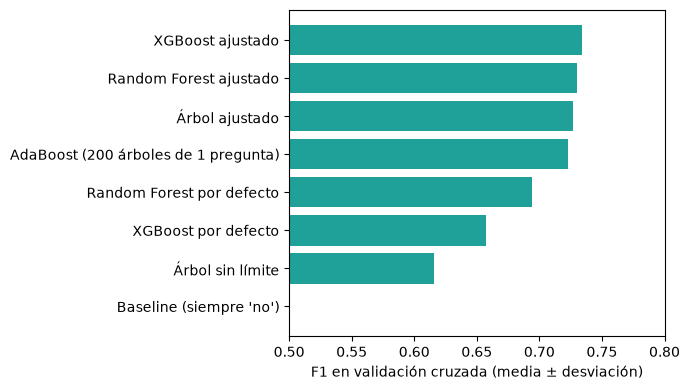

In [35]:
tabla = pd.DataFrame(resultados).sort_values("F1 val", ascending=False).reset_index(drop=True)
display(tabla.round(3))

t = tabla.sort_values("F1 val")
plt.figure(figsize=(7, 4))
plt.barh(t["modelo"], t["F1 val"],  color="#1FA098")
plt.xlabel("F1 en validación cruzada (media ± desviación)")
plt.xlim(0.5, 0.8)
plt.tight_layout(); plt.show()

## 8 · ¿Cuál elegimos?

### Paso 1 · Quitamos los que pierden claramente

| Modelo | F1 val | ¿Por qué lo descartamos? |
|---|---|---|
| Baseline | 0,000 | No encuentra a nadie |
| Árbol sin límite | 0,615 | Memoriza (1,000 en train) |
| XGBoost por defecto | 0,658 | Memoriza (1,000 en train) |
| Random Forest por defecto | 0,694 | Memoriza (1,000 en train) y su versión ajustada es mejor |

Los cuatro que memorizan son los que **no tienen frenos**. Todos los ajustados les ganan.

### Paso 2 · ¿Hay un ganador entre los ajustados?

| Modelo | F1 val | ± F1 val |
|---|---|---|
| XGBoost ajustado | 0,734 | 0,041 |
| Random Forest ajustado | 0,730 | 0,047 |
| Árbol ajustado | 0,727 | 0,045 |
| AdaBoost | 0,723 | 0,047 |


Entre el mejor y el peor hay 0,011. Pero la nota de cada modelo sube y baja unos 0,045 según los socios que le toquen. La diferencia es más pequeña que ese baile: **es un empate.**

Si cambiáramos el reparto de los trozos, el orden podría cambiar. **Es un empate.** Con estos datos no podemos decir que uno acierte más que otro.

### Paso 3 · Desempatamos con otros criterios

Si aciertan lo mismo, nos preguntamos qué más le importa al gimnasio:

| Criterio | Árbol ajustado | Random Forest ajustado | AdaBoost | XGBoost ajustado |
|---|---|---|---|---|
| F1 en validación | 0,727 | 0,730 | 0,723 | 0,734 |
| ¿Se puede explicar con reglas? | **Sí**: «si va menos de 2 días por semana y lleva menos de 6 meses…» | No (300 árboles) | No (200 árboles) | No (cientos de árboles) |
| ¿Cuánto hay que ajustarlo? | Poco | Poco (por defecto ya va bien) | Poco | Mucho (por defecto memoriza) |
| ¿Hace falta instalar algo? | No | No | No | Sí (`pip install xgboost`) |

### Decisión

El gimnasio quiere **saber por qué se va la gente** para llamarles con una oferta adecuada. El árbol ajustado acierta lo mismo que los demás y además se puede leer y explicar a los encargados. - **Es el que menos consume:** es 1 solo árbol. Entrena unas 30 veces más rápido que Random Forest (300 árboles) y ocupa unas 900 veces menos. **Elegimos el árbol ajustado.**

Si al gimnasio solo le importara detectar a quien se va, sin explicaciones, también valdría **Random Forest ajustado**: acierta lo mismo y casi no hay que ajustarlo, pero es más lento y más pesado

> **IMPORTANTE:** el modelo con el número más alto no siempre es el mejor. Si la diferencia es más pequeña que el `±`, es un empate, y se decide con lo que necesita el cliente.

## 9 · Test, una sola vez

Ahora sí abrimos el test, y una sola vez. No sirve para elegir: ya hemos elegido el árbol en el paso 8. Sirve para comprobar que el modelo funciona con 200 socios que nunca ha visto. Si sale parecido a la validación (0,727), la validación nos decía la verdad.

F1 test:        0.680
Recall test:    0.622
Precision test: 0.750
AUC test:       0.797
[[101  17]
 [ 31  51]]


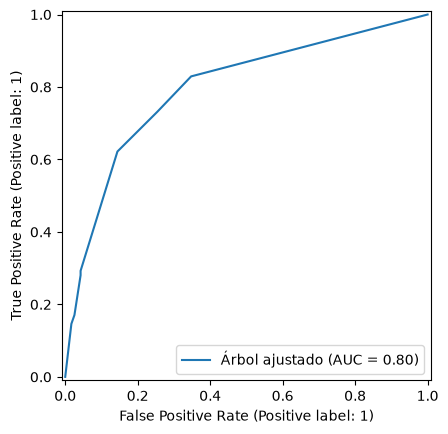

In [36]:
modelo_final = gs_arbol.best_estimator_      # ya está entrenado con todo el train (refit de GridSearchCV)
pred = modelo_final.predict(X_test)
proba = modelo_final.predict_proba(X_test)[:, 1]

print(f"F1 test:        {f1_score(y_test, pred):.3f}")
print(f"Recall test:    {recall_score(y_test, pred):.3f}")
print(f"Precision test: {precision_score(y_test, pred):.3f}")
print(f"AUC test:       {roc_auc_score(y_test, proba):.3f}")
print(confusion_matrix(y_test, pred))
RocCurveDisplay.from_predictions(y_test, proba, name="Árbol ajustado")
plt.show()

**Qué vemos.** F1 en test 0,680, algo por debajo de la validación (0,727). La diferencia es de una desviación (± 0,045): con 200 socios, la nota baila tanto como entre los trozos de validación.

- De los 82 socios que se dan de baja, detecta 51 (recall 0,62) y se le escapan 31. Esos son los errores caros para el gimnasio.
- De cada 4 avisos que da, 3 aciertan (precision 0,75).

No cambiamos de modelo por esta nota: el test confirma, no elige.

#### ¿Y si hubiéramos elegido AdaBoost?

El árbol ajustado ya estaba entrenado porque pasó por `GridSearchCV` (`best_estimator_`). AdaBoost no: `evaluar()` lo entrenó 5 veces para ponerle nota y tiró esos modelos. La variable `ada` sigue siendo solo la receta, así que hay que entrenarla con los 800 socios del train.

| Modelo elegido | Cómo lo recuperamos |
|---|---|
| Árbol, Random Forest o XGBoost ajustados | `gs_arbol.best_estimator_`, `gs_rf.best_estimator_`, `gs_xgb.best_estimator_` (ya entrenados) |
| AdaBoost, o cualquiera «por defecto» | La variable donde lo guardamos + `.fit(X_train, y_train)` |

La celda está comentada a propósito: el test se usa **una sola vez**, con el modelo que ya hemos elegido. No se prueban varios modelos en el test.

In [37]:
# Solo si en el paso 8 hubiéramos elegido AdaBoost (quita los # para usarlo):
# modelo_final = ada.fit(X_train, y_train)     # ahora sí aprende, con los 800 socios del train
# pred = modelo_final.predict(X_test)
# proba = modelo_final.predict_proba(X_test)[:, 1]
# ... y el resto igual que la celda del árbol